# Семинар. Интерполяция сплайнами

**Курс «Численные методы», 2 курс физического факультета СПбГУ**

**План семинара**

1. Задача интерполяции. Глобальная и локальная интерполяция
2. Глобальная интерполяция многочленом Ньютона и феномен Рунге
3. Как бороться с феноменом Рунге: узлы Чебышёва
4. Локальная интерполяция: кусочно-линейная
5. Кубический сплайн: определение, граничные условия, свойства
6. Вывод системы уравнений для моментов
7. Собственная реализация естественного сплайна
8. Задачи
9. Домашнее задание

Приложение: метод прогонки.

**Напоминание по работе с блокнотом**

- Ячейка выполняется сочетанием **Shift + Enter**.
- Ячейки выполняются в том порядке, в котором вы их запускаете, а не в том, в котором они расположены. Если появилась ошибка `NameError: name '...' is not defined`, скорее всего, вы пропустили одну из ячеек выше.
- Если всё окончательно запуталось: меню **Kernel → Restart & Run All** перезапускает Python и выполняет все ячейки сверху вниз.
- Ячейки с пометкой **«Пишем вместе»** мы заполняем вместе на семинаре. Ячейки с готовым кодом нужно просто запустить.

In [2]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.interpolate import CubicSpline

plt.rcParams['figure.figsize'] = (8, 4.5)
plt.rcParams['axes.grid'] = True
np.set_printoptions(precision=3, suppress=True, linewidth=120)

## 1. Задача интерполяции

Пусть на отрезке $[a, b]$ заданы узлы $a = x_0 < x_1 < \dots < x_n = b$ и значения $y_i = f(x_i)$. Требуется построить функцию $g(x)$ из некоторого заданного класса, которая проходит через все точки:

$$g(x_i) = y_i, \qquad i = 0, 1, \dots, n.$$

Откуда берутся такие задачи:
- данные эксперимента или справочные таблицы (например, теплофизические свойства вещества при разных температурах);
- функция, вычисление которой очень дорого (результат другого расчёта);
- нужно вычислять значения, производные или интегралы между узлами.

Всюду на семинаре в качестве примера будем использовать функцию Рунге

$$f(x) = \frac{1}{1 + 25x^2}, \qquad x \in [-1, 1].$$

Зададим её, возьмём 9 равноотстоящих узлов и посмотрим на точки, через которые нужно провести кривую.

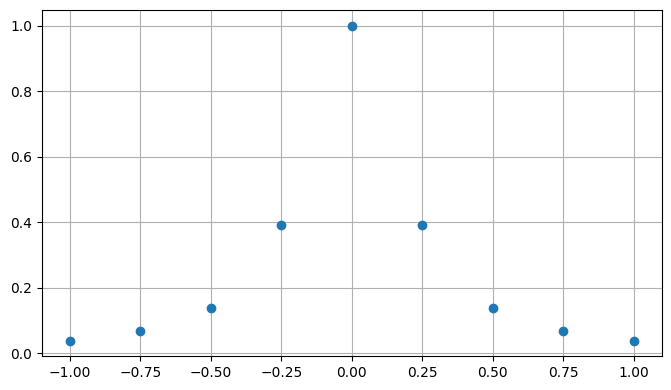

In [3]:
# Пишем вместе:
# 1) функция runge(x) = 1 / (1 + 25 x^2)
# 2) 9 равноотстоящих узлов на [-1, 1] (np.linspace) и значения функции в них
# 3) график точек
def runge(x):
    return 1.0 / (1.0 + 25.0 * x**2)

x = np.linspace(-1, 1, 9)
y = runge(x)
plt.plot(x, y, 'o')
plt.show()

Для графиков и оценки погрешности нам понадобится мелкая сетка `t` на том же отрезке. Нарисуем на ней саму функцию вместе с узлами.

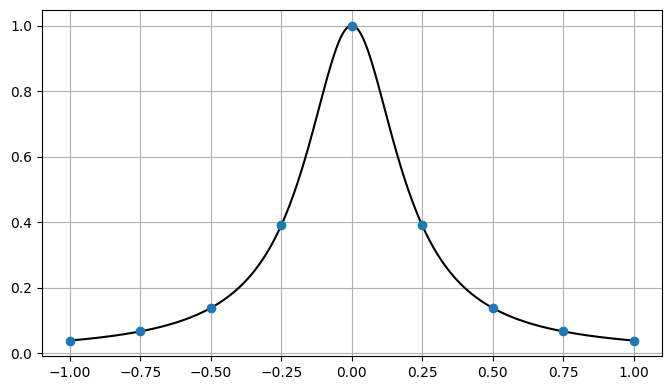

In [4]:
# Пишем вместе:
# 1) концы отрезка a, b и мелкая сетка t из 2001 точки
# 2) график функции на сетке t и точки (x, y)
a, b = -1.0, 1.0
t = np.linspace(a, b, 2001)

plt.plot(t, runge(t), 'k')
plt.plot(x, y, 'o')
plt.show()

Существуют два принципиально разных подхода к интерполяции.

**Глобальная интерполяция.** Одна функция на всём отрезке, например многочлен степени $n$, проходящий через все $n+1$ точек.

**Локальная (кусочная) интерполяция.** На каждом отрезке $[x_{i-1}, x_i]$ строится своя простая функция, использующая только соседние узлы.

## 2. Глобальная интерполяция: многочлен Ньютона

Напомним, что интерполяционный многочлен степени $n$ по $n+1$ точкам существует и единственен. Его удобно записывать в форме Ньютона:

$$P_n(x) = f[x_0] + f[x_0, x_1](x - x_0) + f[x_0, x_1, x_2](x - x_0)(x - x_1) + \dots + f[x_0, \dots, x_n]\prod_{k=0}^{n-1}(x - x_k),$$

где разделённые разности определяются рекуррентно:

$$f[x_i] = y_i, \qquad f[x_i, \dots, x_{i+k}] = \frac{f[x_{i+1}, \dots, x_{i+k}] - f[x_i, \dots, x_{i+k-1}]}{x_{i+k} - x_i}.$$

Коэффициенты $c_k = f[x_0, \dots, x_k]$ вычисляются по таблице разделённых разностей «на месте» (в одном массиве), а значение многочлена — по схеме Горнера:

$$P_n(x) = c_0 + (x - x_0)\Big(c_1 + (x - x_1)\big(c_2 + \dots + (x - x_{n-1})c_n\big)\Big).$$

Функции для вычисления коэффициентов и значений многочлена уже написаны. Запустите ячейку.

In [5]:
def newton_coeff(x, y):
    # Коэффициенты многочлена Ньютона c_k = f[x_0, ..., x_k]
    n = len(x)
    c = np.array(y, dtype=float)
    for k in range(1, n):
        # после шага k в c[i] (i >= k) лежит f[x_{i-k}, ..., x_i]
        c[k:] = (c[k:] - c[k-1:n-1]) / (x[k:] - x[:n-k])
    return c


def newton_eval(c, x, t):
    # Значение многочлена Ньютона в точках t (схема Горнера)
    n = len(x) - 1
    p = c[n] * np.ones_like(t, dtype=float)
    for k in range(n - 1, -1, -1):
        p = p * (t - x[k]) + c[k]
    return p

### Феномен Рунге

Построим интерполяционный многочлен по равноотстоящим узлам. Интуиция подсказывает, что чем больше узлов, тем точнее приближение. Проверим.

In [16]:
# Пишем вместе:
# 1) число отрезков n = 4 и n + 1 равноотстоящих узлов
# 2) коэффициенты многочлена Ньютона
# 3) значения многочлена P на мелкой сетке t
n = 16
x = np.linspace(a, b, n + 1)
c = newton_coeff(x, runge(x))
P = newton_eval(c, x, t)

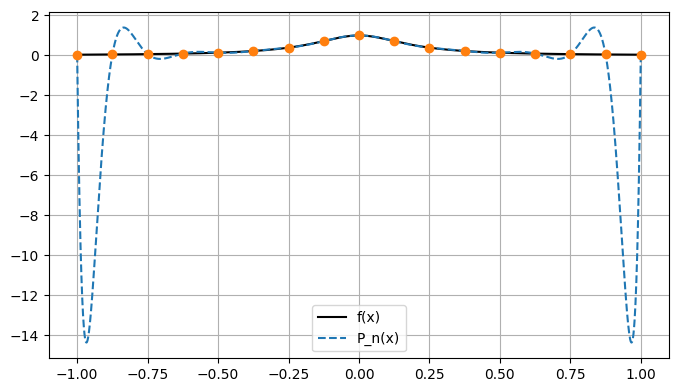

14.39385128501289


In [17]:
# Пишем вместе:
# 1) график функции, многочлена и узлов с легендой
# 2) максимальная погрешность на мелкой сетке: err = max |P - f|
plt.plot(t, runge(t), 'k', label='f(x)')
plt.plot(t, P, '--', label="P_n(x)")
plt.plot(x, runge(x), 'o')
plt.legend()
plt.show()

err = np.max(np.abs(runge(t)-P))
print(err)

**Мини-задача.** Меняйте `n` в ячейке выше (6, 8, 10, 12, ...) и перезапускайте обе ячейки. Что происходит с графиком? При каком чётном $n$ погрешность впервые превышает 10?

Та же картина для нескольких $n$ сразу и таблица погрешностей (просто запустите):

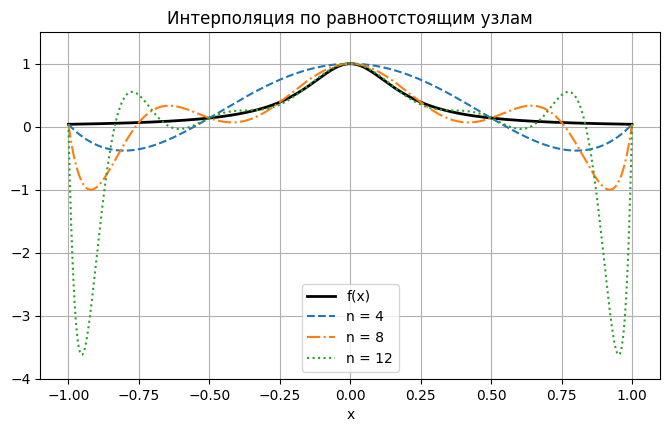

 n    max|f - P_n|
 2    6.462e-01
 4    4.384e-01
 6    6.169e-01
 8    1.045e+00
10    1.916e+00
12    3.663e+00
14    7.195e+00
16    1.439e+01
18    2.919e+01
20    5.982e+01


In [18]:
plt.plot(t, runge(t), 'k', lw=2, label='f(x)')
for n, style in zip([4, 8, 12], ['--', '-.', ':']):
    x = np.linspace(a, b, n + 1)
    c = newton_coeff(x, runge(x))
    plt.plot(t, newton_eval(c, x, t), style, label=f'n = {n}')
plt.ylim(-4, 1.5)
plt.xlabel('x')
plt.title('Интерполяция по равноотстоящим узлам')
plt.legend()
plt.show()

print(' n    max|f - P_n|')
for n in range(2, 21, 2):
    x = np.linspace(a, b, n + 1)
    c = newton_coeff(x, runge(x))
    err = np.max(np.abs(newton_eval(c, x, t) - runge(t)))
    print(f'{n:2d}   {err:10.3e}')

**Феномен Рунге.** При увеличении числа равноотстоящих узлов интерполяционный многочлен не сходится к функции Рунге: у краёв отрезка возникают осцилляции, амплитуда которых растёт с ростом $n$.

Объяснение даёт формула остаточного члена интерполяции:

$$f(x) - P_n(x) = \frac{f^{(n+1)}(\xi)}{(n+1)!}\,\omega_{n+1}(x), \qquad \omega_{n+1}(x) = \prod_{i=0}^{n}(x - x_i).$$

У функции Рунге производные растут очень быстро (быстрее, чем $(n+1)!$ компенсирует), а на равномерной сетке $|\omega_{n+1}(x)|$ велико у краёв отрезка.

Отсюда два пути:
1. Уменьшить $\max|\omega_{n+1}(x)|$ за счёт выбора узлов.
2. Не повышать степень многочлена, а перейти к локальной интерполяции.

## 3. Путь первый: узлы Чебышёва

Величина $\max_{[a,b]}|\omega_{n+1}(x)|$ минимальна, если в качестве узлов взять корни многочлена Чебышёва $T_{n+1}$, пересчитанные на отрезок $[a, b]$:

$$x_k = \frac{a + b}{2} + \frac{b - a}{2}\cos\frac{\pi(2k + 1)}{2(n + 1)}, \qquad k = 0, 1, \dots, n.$$

Вычислим узлы по этой формуле и сравним их расположение с равноотстоящими.

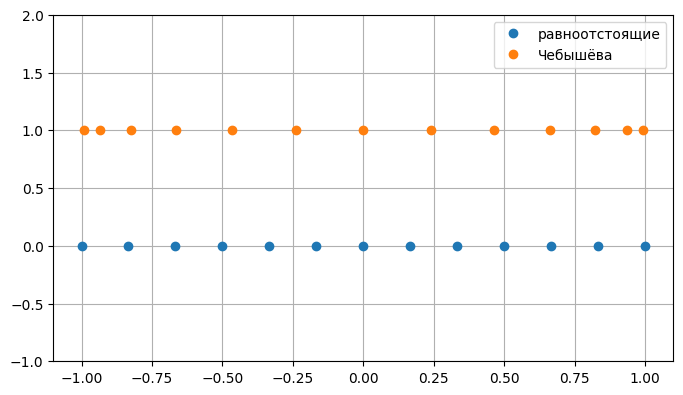

In [26]:
# Пишем вместе:
# 1) n = 12, массив номеров k = 0, 1, ..., n (np.arange)
# 2) узлы Чебышёва x_cheb по формуле (одна строка) и равноотстоящие узлы x_uni
# 3) нарисовать оба набора узлов на разной высоте (np.zeros_like, np.ones_like)
n = 12
k = np.arange(n + 1)
x_cheb = 0.5 * (a + b) + 0.5 * (b - a) * np.cos(0.5 * np.pi * (2 * k + 1) / (n + 1))
x_uni = np.linspace(a, b, n + 1)

plt.plot(x_uni, np.zeros_like(x_uni), 'o', label='равноотстоящие')
plt.plot(x_cheb, np.ones_like(x_cheb), 'o', label='Чебышёва')
plt.legend()
plt.ylim(-1, 2)
plt.show()

Узлы Чебышёва сгущаются к краям отрезка, как раз там, где на равномерной сетке возникали осцилляции. Построим по ним многочлен.

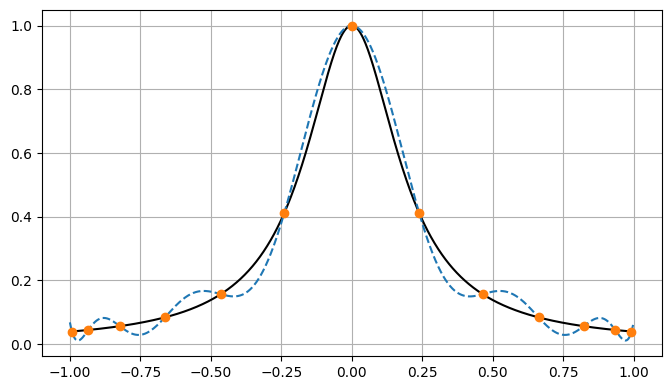

0.06921570780776642


In [27]:
# Пишем вместе:
# 1) многочлен Ньютона по узлам Чебышёва, значения на сетке t
# 2) график и максимальная погрешность

c = newton_coeff(x_cheb, runge(x_cheb))
P = newton_eval(c, x_cheb, t)

plt.plot(t, runge(t), 'k', label='f(x)')
plt.plot(t, P, '--', label='P_n(x), Чеб')
plt.plot(x_cheb, runge(x_cheb), 'o')
plt.show()

print(np.max(np.abs(runge(t) - P)))

То же для нескольких $n$ и таблица погрешностей (просто запустите):

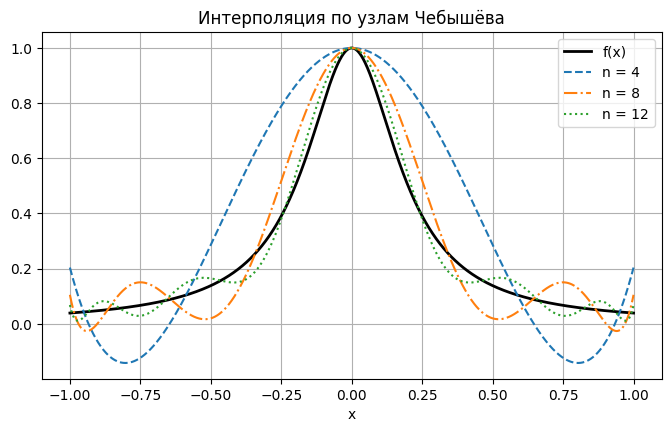

 n    max|f - P_n|
 2    6.006e-01
 4    4.020e-01
 6    2.642e-01
 8    1.708e-01
10    1.092e-01
12    6.922e-02
14    4.660e-02
16    3.261e-02
18    2.249e-02
20    1.533e-02


In [28]:
def chebyshev_nodes(a, b, n):
    # n + 1 узлов Чебышёва на [a, b]
    k = np.arange(n + 1)
    return 0.5 * (a + b) + 0.5 * (b - a) * np.cos(np.pi * (2 * k + 1) / (2 * (n + 1)))


plt.plot(t, runge(t), 'k', lw=2, label='f(x)')
for n, style in zip([4, 8, 12], ['--', '-.', ':']):
    x = chebyshev_nodes(a, b, n)
    c = newton_coeff(x, runge(x))
    plt.plot(t, newton_eval(c, x, t), style, label=f'n = {n}')
plt.xlabel('x')
plt.title('Интерполяция по узлам Чебышёва')
plt.legend()
plt.show()

print(' n    max|f - P_n|')
for n in range(2, 21, 2):
    x = chebyshev_nodes(a, b, n)
    c = newton_coeff(x, runge(x))
    print(f'{n:2d}   {np.max(np.abs(newton_eval(c, x, t) - runge(t))):10.3e}')

**Почему узлов Чебышёва недостаточно?**

1. Узлы Чебышёва помогают, только если мы сами выбираем, где вычислять функцию. На практике данные часто заданы на фиксированной сетке: измерения, таблицы, результаты другого расчёта.
2. Глобальность: изменение одного значения $y_i$ меняет интерполяционный многочлен на всём отрезке (это увидим чуть ниже).
3. Многочлены высокой степени чувствительны к ошибкам в данных и к ошибкам округления.

Поэтому переходим ко второму пути — локальной интерполяции.

## 4. Путь второй: кусочно-линейная интерполяция

Самый простой вариант локальной интерполяции: на каждом отрезке $[x_{i-1}, x_i]$ соединяем соседние точки прямой:

$$g(x) = y_{i-1}\frac{x_i - x}{h_i} + y_i\frac{x - x_{i-1}}{h_i}, \qquad h_i = x_i - x_{i-1}.$$

Оценка погрешности для $f \in C^2[a, b]$ и $h = \max h_i$:

$$\max_{[a,b]}|f(x) - g(x)| \le \frac{h^2}{8}\max_{[a,b]}|f''(x)|.$$

Погрешность стремится к нулю при $h \to 0$ для любой дважды гладкой функции, никакого феномена Рунге нет. В `numpy` такая интерполяция уже реализована: `np.interp(t, x, y)` вычисляет значения ломаной, проходящей через точки `(x, y)`, в точках `t`.

In [ ]:
# Пишем вместе:
# 1) n = 10, равноотстоящие узлы
# 2) кусочно-линейная интерполяция на сетке t через np.interp
# 3) график и максимальная погрешность


**Мини-задача.** Для функции $\sin x$ на отрезке $[0, \pi]$ вычислите максимальную погрешность кусочно-линейной интерполяции при $n = 10$ и $n = 20$ (не забудьте создать для этого отрезка свою мелкую сетку). Во сколько раз уменьшилась погрешность? Согласуется ли это с оценкой $O(h^2)$?

In [ ]:
# Ваш код


Таблица погрешностей для функции Рунге (просто запустите):

In [ ]:
print('  n    max|f - g|')
for n in [4, 8, 16, 32, 64, 128]:
    x = np.linspace(a, b, n + 1)
    print(f'{n:3d}   {np.max(np.abs(np.interp(t, x, runge(x)) - runge(t))):10.3e}')

**Локальность.** Изменим одно значение $y_3$ и посмотрим, как изменятся интерполяционный многочлен и кусочно-линейная интерполяция (просто запустите).

In [ ]:
n = 10
x = np.linspace(a, b, n + 1)
y = runge(x)
y_pert = y.copy()
y_pert[3] += 0.1            # возмущаем одно значение

dP = newton_eval(newton_coeff(x, y_pert), x, t) - newton_eval(newton_coeff(x, y), x, t)
dL = np.interp(t, x, y_pert) - np.interp(t, x, y)

plt.plot(t, dP, label='многочлен Ньютона')
plt.plot(t, dL, label='кусочно-линейная')
plt.plot(x, 0 * x, 'ko', ms=4)
plt.xlabel('x')
plt.title('Изменение интерполянта при возмущении $y_3$ на 0.1')
plt.legend()
plt.show()

Изменение многочлена «расползается» на весь отрезок, а кусочно-линейная интерполяция меняется только на двух соседних отрезках.

**Недостаток кусочно-линейной интерполяции** — изломы в узлах: первая производная разрывна. Для многих задач это неприемлемо: например, если по интерполянту нужно вычислять производные (тепловой поток, скорость) или если нужна гладкая кривая в графике и геометрии.

## 5. Кубический сплайн

### Почему кубический?

Хотим сохранить локальность, но избавиться от изломов. Для этого берём на каждом отрезке многочлен более высокой степени и требуем непрерывности производных в узлах.

Кубический сплайн — минимальная степень, при которой непрерывна вторая производная, то есть кривизна. Именно тогда график выглядит гладким на глаз. Квадратичные сплайны требуют одного дополнительного условия на одном из концов и ведут себя несимметрично, поэтому на практике почти не используются.

Кстати, кусочно-линейная интерполяция — это тоже сплайн, сплайн первой степени.

### Определение

**Кубическим сплайном**, интерполирующим данные $(x_i, y_i)$, называется функция $S(x)$, такая что:
1. на каждом отрезке $[x_{i-1}, x_i]$, $i = 1, \dots, n$, $S(x)$ — многочлен степени не выше 3;
2. $S(x_i) = y_i$, $i = 0, \dots, n$;
3. $S(x) \in C^2[a, b]$, то есть $S$, $S'$ и $S''$ непрерывны во внутренних узлах $x_1, \dots, x_{n-1}$.

### Подсчёт условий

Неизвестных: по 4 коэффициента на каждый из $n$ отрезков, итого $4n$.

Условий:
- интерполяция на обоих концах каждого отрезка: $2n$;
- непрерывность $S'$ во внутренних узлах: $n - 1$;
- непрерывность $S''$ во внутренних узлах: $n - 1$.

Итого $4n - 2$ условия. **Не хватает двух условий** — их задают на концах отрезка. Это граничные условия.

### Типы граничных условий

1. **Естественный (натуральный) сплайн:** $S''(a) = S''(b) = 0$.
2. **Закреплённый сплайн (clamped):** заданы производные на концах, $S'(a) = f'(a)$, $S'(b) = f'(b)$.
3. **Условие «not-a-knot»:** третья производная непрерывна в узлах $x_1$ и $x_{n-1}$. Тогда на первых двух и на последних двух отрезках сплайн — один и тот же многочлен, то есть $x_1$ и $x_{n-1}$ «не являются узлами».
4. **Периодический сплайн:** $S'(a) = S'(b)$, $S''(a) = S''(b)$ (при $y_0 = y_n$). Нужен для периодических функций и замкнутых кривых.

### Чем хорош естественный сплайн

Он не требует знания производных $f$ на концах, а только значений в узлах. Кроме того, он обладает **свойством минимальной кривизны**: среди всех функций $g \in C^2[a, b]$, проходящих через заданные точки, естественный сплайн минимизирует функционал

$$\int_a^b \big(g''(x)\big)^2\,dx.$$

Физический смысл: так изгибается тонкая упругая линейка, закреплённая в точках (энергия изгиба пропорциональна интегралу квадрата кривизны). Английское слово *spline* и означало такую чертёжную линейку.

### Оценки погрешности

Если $f \in C^4[a, b]$ и сплайн закреплённый (или not-a-knot), то

$$\max_{[a,b]}|f - S| \le \frac{5}{384}h^4\max_{[a,b]}|f^{(4)}|, \qquad \max|f' - S'| = O(h^3), \qquad \max|f'' - S''| = O(h^2).$$

Для естественного сплайна всё не так просто, и это мы исследуем в задаче 2.

### Кубический сплайн в `scipy`

Прежде чем разбираться, как устроен сплайн внутри, воспользуемся готовой реализацией `scipy.interpolate.CubicSpline`:

```python
cs = CubicSpline(x, y, bc_type='natural')   # построить сплайн
cs(t)                                       # значения сплайна в точках t
cs(t, 1)                                    # первая производная S'(t)
cs(t, 2)                                    # вторая производная S''(t)
```

Граничные условия задаются параметром `bc_type`:
- `'natural'` — естественный сплайн;
- `'not-a-knot'` — используется по умолчанию, если `bc_type` не указан;
- `bc_type=((1, df_a), (1, df_b))` — закреплённый сплайн с производными `df_a` и `df_b` на концах;
- `'periodic'` — периодический.

In [ ]:
# Пишем вместе:
# 1) n = 8, равноотстоящие узлы, значения функции Рунге
# 2) естественный сплайн cs_nat и сплайн not-a-knot cs_nak


In [ ]:
# Пишем вместе:
# график функции, обоих сплайнов и узлов с легендой


**Мини-задача.** Поменяйте `n` в ячейке выше на 12, 16, 32 и перезапустите обе ячейки. Есть ли феномен Рунге?

Сплайны на графике почти совпадают. Нарисуем их разность, чтобы увидеть, где они отличаются.

In [ ]:
# Пишем вместе:
# график разности двух сплайнов и узлы


Сплайны отличаются в основном у краёв отрезка: граничные условия влияют прежде всего на поведение вблизи концов.

Теперь посмотрим на вторую производную сплайна.

In [ ]:
# Пишем вместе:
# графики второй производной обоих сплайнов (cs(t, 2)) и её значения в узлах


Вторая производная кубического сплайна — **ломаная**: на каждом отрезке кубический многочлен, значит, его вторая производная линейна. У естественного сплайна она равна нулю на концах.

Отсюда идея: если знать значения $S''$ в узлах, то $S''$ восстанавливается на всём отрезке, а вместе с ней и сам сплайн. Эти значения называются **моментами** сплайна. Именно на этом основан способ построения сплайна, который мы сейчас выведем.

## 6. Вывод системы уравнений: метод моментов

Обозначим **моменты** сплайна $M_i = S''(x_i)$, $i = 0, \dots, n$, и шаги $h_i = x_i - x_{i-1}$, $i = 1, \dots, n$.

**Шаг 1.** На отрезке $[x_{i-1}, x_i]$ сплайн — кубический многочлен, значит $S''$ линейна:

$$S''(x) = M_{i-1}\frac{x_i - x}{h_i} + M_i\frac{x - x_{i-1}}{h_i}.$$

Непрерывность $S''$ в узлах выполнена автоматически: в каждом узле $x_i$ оба соседних отрезка дают $M_i$.

**Шаг 2.** Интегрируем дважды и подбираем две константы интегрирования из условий $S(x_{i-1}) = y_{i-1}$, $S(x_i) = y_i$:

$$\boxed{S(x) = M_{i-1}\frac{(x_i - x)^3}{6h_i} + M_i\frac{(x - x_{i-1})^3}{6h_i} + \left(y_{i-1} - \frac{M_{i-1}h_i^2}{6}\right)\frac{x_i - x}{h_i} + \left(y_i - \frac{M_i h_i^2}{6}\right)\frac{x - x_{i-1}}{h_i}}$$

Интерполяционные условия теперь тоже выполнены автоматически. Осталось обеспечить непрерывность $S'$.

**Шаг 3.** Дифференцируем:

$$S'(x) = -M_{i-1}\frac{(x_i - x)^2}{2h_i} + M_i\frac{(x - x_{i-1})^2}{2h_i} + \frac{y_i - y_{i-1}}{h_i} - \frac{(M_i - M_{i-1})h_i}{6}.$$

Производная слева в узле $x_i$ (отрезок $i$) и справа (отрезок $i+1$):

$$S'(x_i - 0) = \frac{h_i}{6}M_{i-1} + \frac{h_i}{3}M_i + \frac{y_i - y_{i-1}}{h_i}, \qquad
S'(x_i + 0) = -\frac{h_{i+1}}{3}M_i - \frac{h_{i+1}}{6}M_{i+1} + \frac{y_{i+1} - y_i}{h_{i+1}}.$$

**Шаг 4.** Приравниваем и умножаем на 6. Получаем для $i = 1, \dots, n-1$:

$$\boxed{h_i M_{i-1} + 2(h_i + h_{i+1}) M_i + h_{i+1} M_{i+1} = 6\left(\frac{y_{i+1} - y_i}{h_{i+1}} - \frac{y_i - y_{i-1}}{h_i}\right)}$$

Это $n - 1$ уравнение на $n + 1$ неизвестную. Два недостающих уравнения дают граничные условия. Для естественного сплайна $M_0 = 0$, $M_n = 0$.

### Матричная форма (естественный сплайн)

Удобно оставить все $n+1$ неизвестных и записать граничные условия как первую и последнюю строки системы:

$$
\begin{pmatrix}
1 & 0 & & & & \\
h_1 & 2(h_1 + h_2) & h_2 & & & \\
 & h_2 & 2(h_2 + h_3) & h_3 & & \\
 & & \ddots & \ddots & \ddots & \\
 & & & h_{n-1} & 2(h_{n-1} + h_n) & h_n \\
 & & & & 0 & 1
\end{pmatrix}
\begin{pmatrix} M_0 \\ M_1 \\ M_2 \\ \vdots \\ M_{n-1} \\ M_n \end{pmatrix}
=
\begin{pmatrix} 0 \\ d_1 \\ d_2 \\ \vdots \\ d_{n-1} \\ 0 \end{pmatrix},
\qquad d_i = 6\left(\frac{y_{i+1} - y_i}{h_{i+1}} - \frac{y_i - y_{i-1}}{h_i}\right).
$$

Плюс такой записи: для других граничных условий меняются только первая и последняя строки.

### Свойства матрицы

Матрица **трёхдиагональная**. Кроме того, у неё **строгое диагональное преобладание** по строкам:

$$2(h_i + h_{i+1}) > h_i + h_{i+1}, \qquad \text{а в граничных строках } 1 > 0.$$

По теореме Гершгорина все собственные значения лежат в кругах с центрами $a_{ii}$ и радиусами $\sum_{j \ne i}|a_{ij}| < |a_{ii}|$, поэтому ноль не является собственным значением. Следовательно, **матрица невырождена, и сплайн существует и единственен.**

Для трёхдиагональных систем существует быстрый метод решения за $O(n)$ операций — метод прогонки (см. приложение). Диагональное преобладание гарантирует его устойчивость. На семинаре мы для простоты будем решать систему стандартной функцией `np.linalg.solve`.

## 7. Собственная реализация естественного сплайна

Ниже три готовые функции:
- `natural_spline_system(x, y)` собирает матрицу $A$ и правую часть $d$ системы для моментов;
- `natural_spline(x, y)` решает систему и возвращает моменты $M_0, \dots, M_n$;
- `spline_eval(x, y, M, t)` вычисляет значения сплайна в точках `t` по формуле в рамке из раздела 6.

**Внимание к индексам.** В формулах $h_i = x_i - x_{i-1}$, $i = 1, \dots, n$. В коде `h = np.diff(x)` даёт `h[0] = x[1] - x[0]`, то есть $h_i$ хранится в `h[i-1]`.

**Поиск отрезка.** Для каждой точки $t$ нужно найти номер отрезка $i$, такой что $x_{i-1} \le t < x_i$. Это делается бинарным поиском, который в `numpy` для целого массива точек реализован функцией `np.searchsorted`.

Запустите ячейку.

In [ ]:
def natural_spline_system(x, y):
    # Матрица A и правая часть d системы для моментов естественного сплайна
    n = len(x) - 1
    h = np.diff(x)                 # h[i-1] = h_i = x_i - x_{i-1}
    A = np.zeros((n + 1, n + 1))
    d = np.zeros(n + 1)
    A[0, 0] = 1.0                  # M_0 = 0
    A[n, n] = 1.0                  # M_n = 0
    for i in range(1, n):
        A[i, i - 1] = h[i - 1]
        A[i, i]     = 2.0 * (h[i - 1] + h[i])
        A[i, i + 1] = h[i]
        d[i] = 6.0 * ((y[i + 1] - y[i]) / h[i] - (y[i] - y[i - 1]) / h[i - 1])
    return A, d


def natural_spline(x, y):
    # Моменты естественного сплайна
    A, d = natural_spline_system(x, y)
    return np.linalg.solve(A, d)


def spline_eval(x, y, M, t):
    # Значения кубического сплайна с моментами M в точках t
    t = np.asarray(t, dtype=float)
    # i такое, что x[i-1] <= t < x[i]; обрезаем, чтобы t = x_n попало в последний отрезок
    i = np.clip(np.searchsorted(x, t, side='right'), 1, len(x) - 1)
    h = x[i] - x[i - 1]
    left, right = x[i] - t, t - x[i - 1]
    return (M[i - 1] * left**3 + M[i] * right**3) / (6.0 * h) \
        + (y[i - 1] - M[i - 1] * h**2 / 6.0) * left / h \
        + (y[i] - M[i] * h**2 / 6.0) * right / h

Посмотрим на матрицу для небольшой **неравномерной** сетки и проверим диагональное преобладание.

In [ ]:
# Пишем вместе:
# 1) неравномерная сетка x = [0, 0.3, 1, 1.4, 2], значения y = sin(x)
# 2) матрица системы A и правая часть d, вывести A


In [ ]:
# Пишем вместе:
# 1) модули диагональных элементов (np.diag)
# 2) суммы модулей внедиагональных элементов по строкам (np.sum(..., axis=1) минус диагональ)
# 3) проверить, что диагональ больше в каждой строке


Вычислим моменты и проверим, что сплайн проходит через узлы.

In [ ]:
# Пишем вместе:
# 1) моменты M
# 2) разность значений сплайна в узлах и y (должны быть нули)


Сравним со `scipy`: моменты должны совпасть с `cs(x, 2)`, а значения — на мелкой сетке.

In [ ]:
# Пишем вместе:
# 1) естественный сплайн из scipy, сравнить наши моменты с cs(x, 2)
# 2) максимальная разность значений на мелкой сетке tt на [0, 2]


Совпадение с точностью до ошибок округления. Наконец, таблица погрешностей нашего сплайна и кусочно-линейной интерполяции для функции Рунге (просто запустите):

In [ ]:
print('  n    сплайн       кусочно-линейная')
for n in [4, 8, 16, 32, 64, 128]:
    x = np.linspace(a, b, n + 1)
    y = runge(x)
    e_s = np.max(np.abs(spline_eval(x, y, natural_spline(x, y), t) - runge(t)))
    e_l = np.max(np.abs(np.interp(t, x, y) - runge(t)))
    print(f'{n:3d}   {e_s:10.3e}   {e_l:10.3e}')

Погрешность сплайна убывает с ростом числа узлов, и при достаточно большом $n$ сплайн намного точнее кусочно-линейной интерполяции при том же числе узлов.

---
## 8. Задачи

### Задача 1. Свои точки

1. Задайте 6–7 точек: либо значения $\sin x$ в нескольких узлах на $[0, 2\pi]$, либо любые придуманные вами числа.
2. Постройте по ним естественный сплайн и сплайн not-a-knot с помощью `CubicSpline`.
3. Нарисуйте оба сплайна и точки на одном графике, а на втором — их разность.
4. Где сплайны отличаются сильнее всего?

In [ ]:
# Ваш код


### Задача 2. Исследование сходимости

Рассмотрим функцию $f(x) = e^x$ на отрезке $[0, 1]$. Будем удваивать число отрезков $n$ и смотреть, во сколько раз уменьшается погрешность:
- если погрешность пропорциональна $h^2$, то при уменьшении шага вдвое она уменьшается в $2^2 = 4$ раза;
- если погрешность пропорциональна $h^4$, то в $2^4 = 16$ раз.

Функция `print_ratios` печатает таблицу погрешностей и отношения соседних погрешностей. Запустите ячейку с ней.

In [ ]:
def print_ratios(ns, errors):
    # Таблица: n, погрешность, во сколько раз погрешность уменьшилась по сравнению с предыдущей
    print('   n     погрешность   отношение')
    for k in range(len(ns)):
        if k == 0:
            print(f'{ns[k]:4d}   {errors[k]:.3e}')
        else:
            print(f'{ns[k]:4d}   {errors[k]:.3e}     {errors[k - 1] / errors[k]:6.2f}')

1. Допишите в цикле строку, вычисляющую максимальную погрешность сплайна на мелкой сетке `tt`. Внимание: погрешность нужно считать именно на мелкой сетке, а не в узлах (в узлах она равна нулю).
2. Запустите ячейку для естественного сплайна. Во сколько раз уменьшается погрешность?
3. Замените `bc_type='natural'` на `bc_type='not-a-knot'`, а затем на закреплённый сплайн `bc_type=((1, 1.0), (1, np.e))` (производная $e^x$ на концах равна $1$ и $e$). Как изменились отношения?

In [ ]:
ns = [4, 8, 16, 32, 64, 128]
tt = np.linspace(0.0, 1.0, 10001)
errors = []
for n in ns:
    x = np.linspace(0.0, 1.0, n + 1)
    cs = CubicSpline(x, np.exp(x), bc_type='natural')
    err = ...   # впишите: максимальная погрешность сплайна cs на сетке tt
    errors.append(err)

print_ratios(ns, errors)


Все три случая на одном графике в двойном логарифмическом масштабе (просто запустите). Прямые $h^4$ и $h^2$ нарисованы для сравнения наклонов.

In [ ]:
def convergence_plot(f, df, xa, xb, ns):
    tt = np.linspace(xa, xb, 20001)
    hs = [(xb - xa) / n for n in ns]
    cases = {'естественный': 'natural',
             'закреплённый': ((1, df(xa)), (1, df(xb))),
             'not-a-knot': 'not-a-knot'}
    for name, bc in cases.items():
        errs = []
        for n in ns:
            x = np.linspace(xa, xb, n + 1)
            errs.append(np.max(np.abs(CubicSpline(x, f(x), bc_type=bc)(tt) - f(tt))))
        plt.loglog(hs, errs, 'o-', label=name)
    hs = np.array(hs)
    plt.loglog(hs, hs**4, 'k:', label='$h^4$')
    plt.loglog(hs, hs**2, 'k--', label='$h^2$')
    plt.xlabel('h')
    plt.ylabel('max|f - S|')
    plt.legend()
    plt.show()


convergence_plot(np.exp, np.exp, 0.0, 1.0, ns)

4. Почему у естественного сплайна порядок хуже? Подсказка: чему равна вторая производная $e^x$ на концах отрезка и чему равна вторая производная естественного сплайна?
5. *(Для быстрых.)* Нарисуйте модуль погрешности естественного сплайна $|f(x) - S(x)|$ при $n = 32$ с помощью `plt.semilogy`. Где сосредоточена погрешность?
6. *(Для быстрых.)* Повторите исследование для $f(x) = \sin x$ на $[0, \pi]$, например с помощью `convergence_plot(np.sin, np.cos, 0.0, np.pi, ns)`. Что изменилось и почему?

In [ ]:
# Ваш код


### Задача 3 (для быстрых). Замкнутая гладкая кривая

Через точки на плоскости, образующие замкнутый контур, можно провести гладкую замкнутую кривую с помощью периодического сплайна. Для этого координаты $x$ и $y$ записывают как функции параметра $s$ и строят сплайны $x(s)$ и $y(s)$.

1. Точки контура заданы ниже (последняя совпадает с первой).
2. Введите параметр $s$ — накопленную длину ломаной: $s_0 = 0$, $s_k = s_{k-1} + |P_k - P_{k-1}|$. Подсказка: длины звеньев — `np.hypot(np.diff(px), np.diff(py))`, накопленная сумма — `np.cumsum`, добавить ноль в начало — `np.concatenate(([0.0], ...))`.
3. Постройте сплайн сразу для обеих координат: `CubicSpline(s, np.column_stack((px, py)), bc_type='periodic')`. Его значения на сетке `ss` — массив из двух столбцов: `curve[:, 0]` и `curve[:, 1]`.
4. Нарисуйте кривую и точки (`plt.axis('equal')`, чтобы не было искажений).

Почему параметр удобно выбирать как длину ломаной, а не просто номер точки?

In [ ]:
phi = np.linspace(0, 2 * np.pi, 10)[:-1]
r = np.array([1.0, 0.6, 1.1, 0.5, 0.9, 0.7, 1.2, 0.4, 0.8])
px = np.concatenate((r * np.cos(phi), [r[0]]))
py = np.concatenate((r * np.sin(phi), [0.0]))

# Ваш код


### Задача 4 (для быстрых). Насколько локален кубический сплайн?

Строго говоря, кубический сплайн не является локальным: система связывает все моменты, и изменение одного $y_i$ меняет сплайн на всём отрезке. Но насколько сильно?

1. Возьмите $n = 20$ равноотстоящих отрезков на $[-1, 1]$ и значения функции Рунге. Измените одно значение $y_{10}$ на $0.1$ (заготовка ниже).
2. Вычислите изменение естественного сплайна $\Delta S(t)$ и изменение многочлена Ньютона $\Delta P(t)$ на сетке `t`.
3. Нарисуйте $|\Delta S|$ и $|\Delta P|$ в логарифмическом масштабе (`plt.semilogy`). Как ведёт себя $|\Delta S|$ при удалении от возмущённого узла?

In [ ]:
n = 20
x = np.linspace(a, b, n + 1)
y = runge(x)
y_pert = y.copy()
y_pert[10] = y_pert[10] + 0.1

# Ваш код


---
## Итоги

- Глобальная интерполяция многочленом высокой степени по равноотстоящим узлам может расходиться (феномен Рунге).
- Узлы Чебышёва решают проблему, но только если узлы можно выбирать.
- Локальная интерполяция сходится при уменьшении шага. Кусочно-линейная даёт порядок $O(h^2)$, но имеет изломы.
- Кубический сплайн — гладкая ($C^2$) кусочно-кубическая функция. Для его построения нужно решить трёхдиагональную систему с диагональным преобладанием.
- Порядок точности сплайна $O(h^4)$ достигается при «правильных» граничных условиях. У естественного сплайна при $f''(a) \ne 0$ или $f''(b) \ne 0$ порядок падает до $O(h^2)$ из-за погрешности у концов.

---
## 9. Домашнее задание

### Основная часть

**ДЗ 1. Сплайн и монотонность: данные с фазовым переходом**

При моделировании плавления часто используют зависимость удельной энтальпии $H$ от температуры $T$. При температуре плавления $T_m$ энтальпия скачком возрастает на величину скрытой теплоты $L$. Модельные данные (в безразмерных единицах):

$$H(T) = \begin{cases} c_s T, & T < T_m, \\ c_l T + L, & T \ge T_m, \end{cases} \qquad c_s = 1,\; c_l = 1.5,\; L = 5,\; T_m = 0.$$

1. Возьмите узлы $T_k$ — 21 равноотстоящая точка на $[-5, 5]$ — и постройте по данным кубический сплайн (`CubicSpline`) и монотонный эрмитов сплайн (`from scipy.interpolate import PchipInterpolator`). Подсказка: значения $H$ в узлах удобно вычислить через `np.where(T < 0, 1.0 * T, 1.5 * T + 5.0)`.
2. Нарисуйте оба интерполянта и их производные $dH/dT$ (эффективную теплоёмкость). Производная `PchipInterpolator` вычисляется так же, как у `CubicSpline`: `p(t, 1)`.
3. Есть ли у кубического сплайна участки, где $dH/dT < 0$? Какой физический смысл это имело бы? Почему у PCHIP такого не происходит?
4. Какой интерполянт вы бы выбрали для задачи о плавлении и почему?

**ДЗ 2. Максимум плотности воды**

Плотность воды $\rho$ (кг/м³) при нормальном давлении:

| $T$, °C | 0 | 2 | 4 | 6 | 8 | 10 | 12 | 14 | 16 | 18 | 20 |
|---|---|---|---|---|---|---|---|---|---|---|---|
| $\rho$ | 999.84 | 999.94 | 999.97 | 999.94 | 999.85 | 999.70 | 999.50 | 999.24 | 998.94 | 998.60 | 998.21 |

1. Постройте по таблице кубический сплайн (not-a-knot) и нарисуйте его вместе с табличными точками.
2. Найдите температуру максимума плотности как корень уравнения $S'(T) = 0$. Пока используйте готовую функцию `from scipy.optimize import brentq`: вызов `brentq(g, 1.0, 8.0)` находит корень функции `g` на отрезке $[1, 8]$. На семинаре по нелинейным уравнениям мы решим эту задачу своими методами.
3. Сравните результат с известным значением $\approx 3.98$ °C. Сравните также с результатом для естественного сплайна.

**ДЗ 3. Точность производных сплайна**

Для $f(x) = e^x$ на $[0, 1]$ и закреплённого сплайна определите, во сколько раз уменьшается погрешность первой производной $\max|f' - S'|$ и второй производной $\max|f'' - S''|$ при удвоении $n$ (используйте `print_ratios` и `cs(tt, 1)`, `cs(tt, 2)`). Согласуется ли это с теорией ($O(h^3)$ и $O(h^2)$)?

### Задачи повышенной сложности (по желанию)

**ДЗ 4. Метод прогонки.** Реализуйте функцию `tridiag_solve(a, b, c, d)` по формулам из приложения. Проверьте её на случайной системе с диагональным преобладанием, сравнив с `np.linalg.solve`. Напишите функцию `natural_spline_tridiag(x, y)`, вычисляющую моменты естественного сплайна прогонкой, и сравните время работы с `natural_spline` при $n = 2000$. Объясните результат.

**ДЗ 5. Закреплённый сплайн своими руками.** Для закреплённого сплайна первая и последняя строки системы заменяются на

$$2h_1 M_0 + h_1 M_1 = 6\left(\frac{y_1 - y_0}{h_1} - f'_a\right), \qquad h_n M_{n-1} + 2h_n M_n = 6\left(f'_b - \frac{y_n - y_{n-1}}{h_n}\right).$$

Выведите эти формулы из выражения для $S'(x)$ в разделе 6, реализуйте функцию `clamped_spline(x, y, dfa, dfb)` и сравните её с `CubicSpline(x, y, bc_type=((1, dfa), (1, dfb)))`.

**ДЗ 6. Неравномерная сетка.** Функция $f(x) = \tanh(50x)$ на $[-1, 1]$ почти постоянна везде, кроме узкой области около нуля. Сравните погрешность естественного сплайна по $n = 40$ равноотстоящим узлам и по сетке с тем же числом узлов, сгущённой к нулю: $x_k = \sinh(\beta\xi_k) / \sinh\beta$, где $\xi_k$ — равномерная сетка на $[-1, 1]$. Подберите $\beta$, при котором погрешность минимальна.

**ДЗ 7. Сглаживающий сплайн.** Сгенерируйте зашумлённые данные: $y_i = \sin(2\pi x_i) + \varepsilon_i$, $\varepsilon_i \sim \mathcal{N}(0, 0.1^2)$, 50 случайных точек на $[0, 1]$. Сравните интерполяционный кубический сплайн и сглаживающий сплайн `scipy.interpolate.make_smoothing_spline`. Почему интерполировать зашумлённые данные — плохая идея? Как выглядят производные обоих сплайнов?

---
## Приложение. Метод прогонки

Метод Гаусса для плотной матрицы требует $O(n^3)$ операций и $O(n^2)$ памяти. Для трёхдиагональной системы существует метод за $O(n)$ — **метод прогонки** (алгоритм Томаса).

Запишем систему в виде

$$a_i x_{i-1} + b_i x_i + c_i x_{i+1} = d_i, \qquad i = 0, 1, \dots, n, \qquad a_0 = 0,\; c_n = 0.$$

Здесь $a_i$ — поддиагональ, $b_i$ — главная диагональ, $c_i$ — наддиагональ.

**Идея.** Ищем решение в виде $x_i = \alpha_{i+1}x_{i+1} + \beta_{i+1}$. Подставляя $x_{i-1} = \alpha_i x_i + \beta_i$ в $i$-е уравнение, получаем рекуррентные формулы.

**Прямой ход** (вычисляем прогоночные коэффициенты):

$$\alpha_1 = -\frac{c_0}{b_0}, \quad \beta_1 = \frac{d_0}{b_0}; \qquad
\alpha_{i+1} = -\frac{c_i}{b_i + a_i\alpha_i}, \quad \beta_{i+1} = \frac{d_i - a_i\beta_i}{b_i + a_i\alpha_i}, \quad i = 1, \dots, n-1.$$

**Обратный ход:**

$$x_n = \frac{d_n - a_n\beta_n}{b_n + a_n\alpha_n}; \qquad x_i = \alpha_{i+1}x_{i+1} + \beta_{i+1}, \quad i = n-1, \dots, 0.$$

**Устойчивость.** Если $|b_i| \ge |a_i| + |c_i|$ и хотя бы для одного $i$ неравенство строгое, то $|\alpha_i| \le 1$, знаменатели не обращаются в ноль и ошибки округления не нарастают. Для матрицы сплайна это выполнено.